In [1]:
import os
os.chdir('D:/tmp_workplace/dynamic_structure/250530/CoV_all_structure_predict/PEDV/cell')
import numpy as np
from scipy import sparse
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [2]:
def get_matrix_npz(M1,M2):
    '''
    use rri-matrix dump result to creat matrix 
    '''
    S1 = sparse.coo_matrix((M1['value'],(np.asarray(M1['S'], dtype= 'i4'),np.asarray(M1['E'], dtype= 'i4')))).toarray()
    S2 = sparse.coo_matrix((M2['value'],(np.asarray(M2['E'], dtype= 'i4'),np.asarray(M2['S'], dtype= 'i4')))).toarray()
    matrix = np.zeros((max(S1.shape),max(S1.shape)))
    matrix[np.nonzero(S1)] = S1[np.nonzero(S1)]
    matrix[np.nonzero(S2)] = S2[np.nonzero(S2)]
    return matrix

def extract_matrix(file_name,res):
    data = np.loadtxt(file_name, usecols=[0,1,2], dtype=[('S','<i4'),('E','<i4'),('value','<f8')])
    data['S'] = data['S'] / res
    data['E'] = data['E'] / res
    data['value'][data['value'] < 0] = 0
    data['value'][np.isnan(data['value'])] = 0
    matrix = get_matrix_npz(data,data)
    return matrix

def load_fasta(fasta_path, select_id=None):
    '''
    fasta_dict      {id : seq list}
    '''
    #fasta_path:in file
    #select_id:id list
    fasta_dict = {}
    fasta = open(fasta_path,'r')
    for line in fasta:
        if line.startswith(">"):
            seqid = line.strip().split()[0][1:]
            fasta_dict[seqid] = ''
        else:
            fasta_dict[seqid] += line.strip().upper()
    fasta.close()
    if select_id:
        select_dict = {}
        for select in select_id:
            test = fasta_dict.get(select)
            if test:
                select_dict[select] = list(test)
            else:
                print("seq is not in fasta",select)
        if  (len(select_dict) != 0):
            return select_dict
        else:
            print('all select not in fasta')
    else:
        return fasta_dict
    
def make_basepair_matrix(sequence_list,length):
    pairs = ['AT','TA','GC','CG','TG','GT']
    tmp = np.zeros((length,length))
    for row in range(tmp.shape[0]):
        for col in range(row,length):
            if sequence_list[row]+sequence_list[col] in pairs:
                tmp[row,col] = 1
    return tmp

def load_pair_bedpe(in_bedpe):
    pairs = []
    ib = open(in_bedpe, "r")
    for line in ib:
        line = line.strip().split()
        if 'chrom1' in line:
            continue
        else:
            left = int(line[1])
            right = int(line[4])
            if left > right:
                continue
            pairs.append((left,right))
    ib.close()
    return pairs

def calculate_pair_distance(pairs_list):
    distance = []
    for pair in pairs_list:
        distance.append(pair[1]-pair[0]+1)
    return distance

def calculate_pair_score(pairs_list,matrix):
    score = []
    for pair in pairs_list:
        score.append(matrix[int(pair[0]/10),int(pair[1]/10)])
    return score

def calculate_pair_proportion(pairs,rri_matrix):
    #tmp_rri_matrix = np.zeros_like(rri_matrix)
    #(x,y) = np.diag_indices_from(rri_matrix)
    #tmp_rri_matrix[x,y] = rri_matrix[x,y].copy()
    #x = np.delete(x, 0)
    #y = np.delete(y, -1)
    #for i in np.arange(300-1):
    #    tmp_rri_matrix[x,y] = rri_matrix[x,y].copy()
    #    tmp_rri_matrix[y,x] = rri_matrix[y,x].copy()
    #    x = np.delete(x, 0)
    #    y = np.delete(y, -1)
    row_sums = np.sum(rri_matrix, axis=1)
    denominator = row_sums[:, np.newaxis] * row_sums[np.newaxis, :]
    proportion_matrix = np.zeros_like(rri_matrix)
    proportion_matrix[denominator>0] = rri_matrix[denominator>0] / np.sqrt(denominator[denominator>0])

    proportion = []
    for pair in pairs:
        left_pair = pair[0]
        right_pair = pair[1]
        pair_proportion = proportion_matrix[int(left_pair/10),int(right_pair/10)]
        if pair_proportion == None:
            pair_proportion = 0
        proportion.append(pair_proportion)

    return proportion

def load_files_name(file):
    file_names = []
    with open(file,'r')as f:
        for line in f:
            if 'chrom' in line:
                continue
            else:
                sub = line.strip().split()
                prefix = "_".join([sub[1],sub[2],sub[4],sub[5]]) + '_structure1.bedpe'
                file_names.append(prefix)
    return file_names

def calculate_genetic_stability(pairs,mafft,seq,seq_id):
    seq2mafft = {}
    mk_mafft = mafft[seq_id]
    gap = 0
    for index,symbol in enumerate(seq):
        m_symbol = mk_mafft[index+gap]
        while m_symbol != symbol:
            gap += 1
            m_symbol = mk_mafft[index+gap]
        seq2mafft[index] = index+gap

    stability = []
    match = ['AT','TA','GC','CG','TG','GT']
    for pair in pairs:
        raw = seq[pair[0]] + seq[pair[1]]
        for mafft_seq in mafft.values():
            tmp = mafft_seq[seq2mafft[pair[0]]] + mafft_seq[seq2mafft[pair[1]]]
            if tmp == raw:
                stability.append(1)
            elif (tmp != raw) and (tmp in match):
                stability.append(0.5)
            else:
                stability.append(0)
    return stability

def create_all_partition_matrixs(file_path,length):
    fileprefixs = []
    with open(file_path+'partition_file_id.txt',"r")as f:
        for line in f:
            fileprefixs.append(line.strip())
    tmp_matrix = np.zeros((length,length))
    for fileprefix in fileprefixs:
        fileprefix_replace = fileprefix.replace(".txt","")
        sub = fileprefix_replace.split("_")
        left_start = int(sub[0])
        right_start = int(sub[2])
        tmp = open(file_path+fileprefix, 'r')
        for index, line in enumerate(tmp):
            if index < 2:
                continue
            else:
                tmp_sub = line.strip().split()
                left = int(tmp_sub[0]) - 1 + left_start
                right = int(tmp_sub[1]) - 1 + right_start
                if float(tmp_sub[2]) > 0:
                    tmp_matrix[left,right] = 1
                    tmp_matrix[right,left] = 1
        tmp.close()
    
    (x,y) = np.diag_indices_from(tmp_matrix)
    final_ma = np.zeros_like(tmp_matrix)
    x = np.delete(x, 0)
    y = np.delete(y, -1)
    for i in np.arange(3000-1):
        final_ma[x,y] = tmp_matrix[x,y].copy()
        final_ma[y,x] = tmp_matrix[y,x].copy()
        x = np.delete(x, 0)
        y = np.delete(y, -1)
    return final_ma

def get_shannon(matrix, res):
    #(x,y) = np.diag_indices_from(matrix)
    #shannon_ma = np.zeros_like(matrix)
    shannon_ma = matrix.copy()
    shan_out = []
    true_shan_out = []
    #x = np.delete(x, 0)
    #y = np.delete(y, -1)
    #for i in np.arange(n-1):
    #    shannon_ma[x,y] = matrix[x,y].copy()
    #    shannon_ma[y,x] = matrix[y,x].copy()
    #    x = np.delete(x, 0)
    #    y = np.delete(y, -1)
    shannon_sum = shannon_ma.sum(axis=1)
    p_ma = shannon_ma / shannon_sum
    p_ma[np.isnan(p_ma)] = 0
    for i,arrs in enumerate(p_ma.T):
        p = arrs[arrs>0]
        shan = np.sum(p*np.log2(p)) * -1
        shan_out.append(shan)
        for iters in range(res):
            true_shan_out.append(shan)       
    return np.array(shan_out), np.array(true_shan_out)

def calculate_pair_shannon(pairs_list,shannon_list):
    shannon = []
    for pair in pairs_list:
        shannon.append(shannon_list[pair[0]]*shannon_list[pair[1]])
    return shannon

In [3]:
length = 28044

rri_matrix = extract_matrix('PEDV_merge_cell_ric_10_KR.matrix',10)

global_shannon = get_shannon(rri_matrix,10)[1][:length]

#file_path = 'D:/tmp_workplace/dynamic_structure/sars2_partition_5000_3000/'
#bp_matrix = create_all_partition_matrixs(file_path,length)

seq_id = 'MK584552.1'
seq = load_fasta('MK584552_md.fasta',[seq_id])[seq_id]
mafft = load_fasta('PEDV_complete_filter_mafft.fasta')

files = load_files_name('clusters_longer_than_3000.bedpe')

avg_pair_distance = []
sum_ric_score = []
#avg_bp_proportion = []
avg_genetic_stability = []
avg_shannon = []
prefix = []

for file in files:
    file_name = './ct_bedpe_annotation/'+file
    if not os.path.exists(file_name):
        print('end')
        continue
    prefix.append(file)
    
    pairs = load_pair_bedpe(file_name)
    distance = calculate_pair_distance(pairs)
    avg_pair_distance.append(np.mean(distance))
    ric_score = calculate_pair_score(pairs,rri_matrix)
    sum_ric_score.append(np.sum(ric_score))
    #proportion = calculate_pair_proportion(pairs,rri_matrix)
    #avg_bp_proportion.append(np.mean(proportion))
    stability = calculate_genetic_stability(pairs,mafft,seq,seq_id)
    avg_genetic_stability.append(np.mean(stability))
    shannon = calculate_pair_shannon(pairs,global_shannon)
    avg_shannon.append(np.mean(shannon))

C:\Users\11509\AppData\Local\Temp\ipykernel_3640\3505057261.py:201: RuntimeWarning: invalid value encountered in divide
  p_ma = shannon_ma / shannon_sum


In [4]:
avg_pair_distance_normal = [x / length * 100 for x in avg_pair_distance]

In [5]:
# 计算均值
shannon_mean = np.nanmean(avg_shannon)
ric_mean = np.nanmean(sum_ric_score)
gs_mean = np.nanmean(avg_genetic_stability)

# 获取同时大于均值的元素的索引
above_mean_indices = np.where(
    (np.less(avg_shannon, shannon_mean)) & 
    (np.greater(sum_ric_score, ric_mean))
)[0]

select_file_name = [prefix[i] for i in above_mean_indices]
select_pair = [avg_pair_distance[i] for i in above_mean_indices]
#select_bp = [avg_bp_proportion[i] for i in above_mean_indices]
select_shannon = [avg_shannon[i] for i in above_mean_indices]
select_ric = [sum_ric_score[i] for i in above_mean_indices]
select_gs = [avg_genetic_stability[i] for i in above_mean_indices]

# 将所有列表打包成元组列表
zipped_lists = list(zip(select_file_name, select_pair, select_shannon, select_ric, select_gs))

# 按 select_ric 列表降序排序，同时保持其他列表元素的对应关系
# 使用 lambda 表达式指定排序键为 select_ric 元素
sorted_pairs = sorted(zipped_lists, key=lambda x: (x[3],-x[2]), reverse=True)

with open('./wc/select_long_range_structure.info','w')as f:
    f.write('select_file_name'+'\t'+'select_pair'+'\t'+'select_shannon'+'\t'+'select_ric'+'\t'+'select_gs'+'\n')
    for i in sorted_pairs:
        f.write(i[0]+'\t'+str(i[1])+'\t'+str(i[2])+'\t'+str(i[3])+'\t'+str(i[4])+'\n')

In [7]:
with open("./wc/all_long_range.info","w")as f:
    f.write('file_name'+'\t'+'select_pair'+'\t'+'shannon'+'\t'+'ric'+'\t'+'gs'+'\n')

    for i in range(len(prefix)):
        tmp_pair = avg_pair_distance[i]
        tmp_shannon = avg_shannon[i]
        tmp_ric = sum_ric_score[i]
        tmp_gs = avg_genetic_stability[i]
        tmp_prefix = prefix[i]
    
        f.write(f"{tmp_prefix}\t{tmp_pair}\t{tmp_shannon}\t{tmp_ric}\t{tmp_gs}\n")

In [6]:
print(len(sum_ric_score))
print(len(avg_shannon))
print(len(avg_pair_distance_normal))
print(len(avg_genetic_stability))

421
421
421
421


In [ ]:
total_index = [i for i in range(len(sum_ric_score))]
not_above_mean_indices = [i for i in total_index if i not in above_mean_indices]

upper_sum_ric_score = [sum_ric_score[i] for i in above_mean_indices]
upper_avg_shannon = [avg_shannon[i] for i in above_mean_indices]
upper_avg_pair_distance_normal = [avg_pair_distance_normal[i] for i in above_mean_indices]
upper_avg_genetic_stability = [avg_genetic_stability[i] for i in above_mean_indices]

lower_sum_ric_score = [sum_ric_score[i] for i in not_above_mean_indices]
lower_avg_shannon = [avg_shannon[i] for i in not_above_mean_indices]
lower_avg_pair_distance_normal = [avg_pair_distance_normal[i] for i in not_above_mean_indices]
lower_avg_genetic_stability = [avg_genetic_stability[i] for i in not_above_mean_indices]

vmin = np.nanmin(upper_avg_genetic_stability+lower_avg_genetic_stability)
vmax = np.nanmax(upper_avg_genetic_stability+lower_avg_genetic_stability)

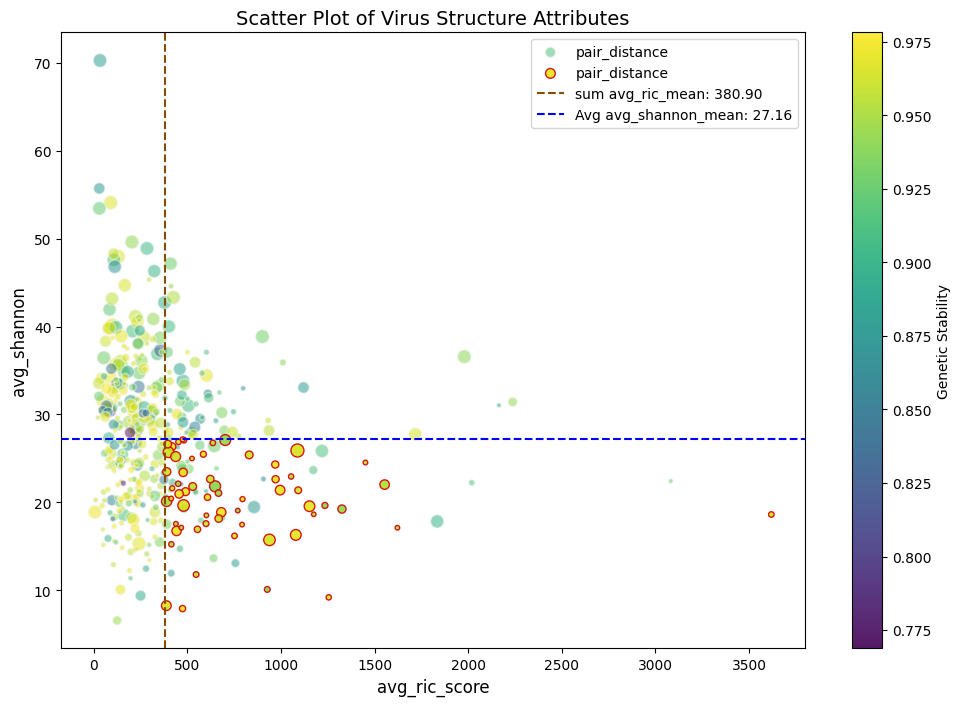

In [ ]:
# 设置画布大小
fig = plt.figure(figsize=(12, 8))

# 绘制散点图
scatter = plt.scatter(lower_sum_ric_score, lower_avg_shannon, 
                      s=lower_avg_pair_distance_normal,  # 圆点大小
                      c=lower_avg_genetic_stability,  # 圆点颜色
                      cmap='viridis',  # 颜色映射
                      alpha=0.5,  # 透明度
                      edgecolors="#F9F6F6",  # 边框颜色
                      linewidth=1,
                      label='pair_distance',
                      vmin=vmin, vmax=vmax )  # 边框宽度

scatter = plt.scatter(upper_sum_ric_score, upper_avg_shannon, 
                      s=upper_avg_pair_distance_normal,  # 圆点大小
                      c=upper_avg_genetic_stability,  # 圆点颜色
                      cmap='viridis',  # 颜色映射
                      alpha=0.9,  # 透明度
                      edgecolors="#D20103",  # 边框颜色
                      linewidth=1,
                      label='pair_distance',
                      vmin=vmin, vmax=vmax )  # 边框宽度

# 添加颜色条
plt.colorbar(scatter, label='Genetic Stability')

# 设置标题和标签
plt.title('Scatter Plot of Virus Structure Attributes', fontsize=14)
plt.xlabel('avg_ric_score', fontsize=12)
plt.ylabel('avg_shannon', fontsize=12)

# 调整布局
#plt.tight_layout()

# 计算并绘制 avg_bp_proportion 和 avg_pair_distance 的平均值的虚线
ric_mean = np.nanmean(sum_ric_score)
vline = plt.axvline(x=ric_mean, color='#874B01', linestyle='--', label=f'sum avg_ric_mean: {ric_mean:.2f}')

shannon_mean = np.nanmean(avg_shannon)
hline = plt.axhline(y=shannon_mean, color='blue', linestyle='--', label=f'Avg avg_shannon_mean: {shannon_mean:.2f}')

# 添加图例
plt.legend()
#plt.savefig("long_range_structure_scatter_plot.pdf", format="pdf", bbox_inches="tight")
# 显示图像
plt.show()